# Causal success API

- This notebook explores `causal_success_utils`, an agent-based simulation in
  which agents with different talents meet lucky and unlucky events over
  time
- The running example is a population of 20 agents over 10 periods, small
  enough to look at every agent
- The full analysis, with causal inference and policy comparisons, is in
  `causal_success_example.ipynb`
- The pedagogical arc:
  - Primitives: one agent, its talents, and how events change its capital
  - Composition: a population, a simulation, and the results table
  - Patterns: inequality, policies, plots, and a Bayesian estimate of the
    effect of luck

In [1]:
%load_ext autoreload
%autoreload 2

import logging

import numpy as np
import pandas as pd

In [2]:
import helpers.hintrospection as hintros
import helpers.hnotebook as hnotebook

import causal_success_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

## Library Overview

- **What problem it solves**: two agents with the same talent can end up with
  very different capital, and the simulation shows how much of the outcome
  comes from talent and how much from luck
- **Key abstraction**: an `Agent` with fixed talents and a capital that each
  event multiplies by a random factor
- **Mental model**:

| Object | Description | Comments |
|--------|-------------|----------|
| `Agent(agent_id, intensity, iq, networking)` | One person | Talents in [0, 1], capital starts at 1.0 |
| `Agent.apply_event(event_type, impact)` | One lucky or unlucky event | Multiplies the capital |
| `create_population(n_agents=, seed=)` | Agents with random talents | Talents drawn from N(0.5, 0.15) |
| `run_simulation(agents, n_periods=, ...)` | Events over time | Changes the agents in place |
| `run_policy_simulation(agents, policy=, ...)` | Give resources, then simulate | `egalitarian`, `meritocratic`, ... |
| `get_results_dataframe(agents)` | One row per agent | Talents, capital, event counts |
| `generate_summary_statistics(agents)` | Inequality metrics | Gini, top and bottom shares |
| `fit_bayesian_luck_model(df)` | Posterior of the effect of luck | Needs PyMC and ArviZ |

- **Key classes**:
  - `Agent`: the talents, capital, event counts, and capital history of one
    person
- **Notation** of the white paper (section "Skill-Luck Decomposition"):
  - $Y$: the final `capital` of an agent
  - $\bar{Y}_A = E[Y \mid S_A, I_A]$: the capital expected from the talents
    of agent $A$
  - $L_A(Y) = Y - \bar{Y}_A$: the luck component of the capital
  - The code uses the word "capital" for $Y$, since $C_A(E)$ is reserved for
    control in the paper

# Part 1: One agent

## Cell 1.1: Creating an agent

In [3]:
# Agent: the core abstraction of the simulation.
#
# - Each agent has 3 talents in [0, 1] and a starting capital
#   - `intensity`: how often the agent meets events, good and bad
#   - `iq`: the chance of turning a lucky event into a gain
#   - `networking`: the chance of sharing a neighbor's lucky event
# - Talents never change, capital changes with every event
# - `create_population()` draws talents from N(0.5, 0.15), clipped to [0, 1],
#   so values far from 0.5 are rare
print("An agent has fixed talents and a capital that events change.")

An agent has fixed talents and a capital that events change.


In [4]:
# Create one agent with chosen talents.
person = utils.Agent(agent_id=0, intensity=0.7, iq=0.6, networking=0.4)
display(pd.Series(person.talent, name="talent"))
# Outcome: the 3 talents as given and an initial capital of 1.0.

intensity          0.7
iq                 0.6
networking         0.4
initial_capital    1.0
Name: talent, dtype: float64

In [5]:
# Combine the talents into a single number.
print("person.talent_norm=", person.talent_norm)
# Outcome: about 1.418, the Euclidean norm of the 4 values above.

person.talent_norm= 1.4177446878757824


In [6]:
# Compute how often the agent meets an event.
print("person.get_event_probability()=", person.get_event_probability())
# Outcome: about 0.599, a sigmoid of the intensity that is 0.5 at
# `intensity=0.5`.

person.get_event_probability()= 0.598687660112452


**Key observations**:

- An intensity of 0.7 gives an exposure probability of about 0.60, above the
  0.5 of an average agent
- The talent norm summarizes ability, but it does not set the outcome: the
  events the agent meets do

## Cell 1.2: Applying events

In [7]:
# Apply a lucky event with a 30% gain.
person.apply_event("lucky", 0.30)
print("person.capital=", person.capital)
# Outcome: 1.3.

person.capital= 1.3


In [8]:
# Apply an unlucky event with a 20% loss.
person.apply_event("unlucky", 0.20)
print("person.capital=", person.capital)
# Outcome: 1.04, i.e., 20% of 1.30 and not of 1.00.

person.capital= 1.04


In [9]:
# Apply another lucky event with a 25% gain.
person.apply_event("lucky", 0.25)
print("person.capital=", person.capital)
# Outcome: 1.30.

person.capital= 1.3


In [10]:
# Show the event counts and the capital after each event.
print("person.lucky_events=", person.lucky_events)
print("person.unlucky_events=", person.unlucky_events)
display(pd.Series(person.capital_history, name="capital"))
# Outcome: 2 lucky events, 1 unlucky event, and 4 capital values starting at
# 1.0.

person.lucky_events= 2
person.unlucky_events= 1


0    1.00
1    1.30
2    1.04
3    1.30
Name: capital, dtype: float64

**Key observations**:

- Each event multiplies the capital, so a gain or a loss is a percentage of
  the current capital
- Early gains raise the base of every later event, and early losses shrink
  it, so the order of events matters

In [11]:
hintros.print_obj_info(utils.Agent)

**Agent**
- `apply_event(self, event_type: str, impact: float) -> None`: Apply an event to capital using multiplicative dynamics...
- `get_event_probability(self) -> float`: Probability of encountering an event based on intensity...

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask537_Review_students_research_projects/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_utils.py#L67


# Part 2: A population over time

## Cell 2.1: Creating a population

In [12]:
# Create 20 agents with random talents.
n_agents = 20
seed = 42
agents = utils.create_population(n_agents=n_agents, seed=seed)
print("len(agents)=", len(agents))
# Outcome: 20.

len(agents)= 20


In [13]:
# Show the talents of the first 5 agents.
df_talents = pd.DataFrame(
    [{"id": a.id, **a.talent, "capital": a.capital} for a in agents]
)
display(df_talents.head())
# Outcome: different talents, and the same capital of 1.0 for everyone.

,id,intensity,iq,networking,initial_capital,capital
0,0,0.545708,0.344002,0.612568,1.0,1.0
1,1,0.641085,0.207345,0.304673,1.0,1.0
2,2,0.519176,0.452564,0.497480,1.0,1.0
3,3,0.372043,0.631910,0.616669,1.0,1.0
4,4,0.509905,0.669086,0.570126,1.0,1.0


In [14]:
# Summarize the intensity over the population.
display(df_talents["intensity"].describe())
# Outcome: a mean of 0.527, a standard deviation of 0.123, and values between
# 0.371 and 0.821.

count    20.000000
mean      0.527104
std       0.123382
min       0.371106
25%       0.422126
50%       0.525990
75%       0.598651
max       0.821247
Name: intensity, dtype: float64

**Key observations**:

- The talents cluster near 0.5, as drawn
- All agents start with a capital of 1.0, so any inequality later comes from
  the events and not from the starting point

## Cell 2.2: Running a short simulation

In [15]:
# Run 10 periods with 3 lucky and 3 unlucky events each.
n_periods = 10
n_events = 3
agents = utils.run_simulation(
    agents,
    n_periods=n_periods,
    n_lucky_events_per_period=n_events,
    n_unlucky_events_per_period=n_events,
    seed=seed,
)
df_results = utils.get_results_dataframe(agents)
display(df_results[["id", "capital", "lucky_events", "unlucky_events"]].head())
# Outcome: agent 2 had 4 lucky events and 1 unlucky event and is at 1.63,
# while agents 3 and 4 had 2 unlucky events each and are below 0.8.

,id,capital,lucky_events,unlucky_events
0,0,0.873118,0,1
1,1,0.996856,1,2
2,2,1.633899,4,1
3,3,0.761320,0,2
4,4,0.727726,0,2


In [16]:
# Compare the poorest and the richest agent.
min_capital = df_results["capital"].min()
max_capital = df_results["capital"].max()
print("min_capital=", min_capital)
print("max_capital=", max_capital)
print("spread=", max_capital / min_capital)
# Outcome: capital goes from 0.46 to 1.63, a spread of 3.5x.

min_capital= 0.46362849550127133
max_capital= 1.6338987774310405
spread= 3.5241552089340034


**Key observations**:

- After 10 periods, capital spreads by a factor of 3.5 even though everyone
  started at 1.0
- The agents ahead are those with more lucky than unlucky events

## Cell 2.3: The results table

In [17]:
# Show the columns of the results table.
print("df_results.shape=", df_results.shape)
print("df_results.columns=", list(df_results.columns))
# Outcome: 20 rows, one per agent, with the talents, the talent norm, the
# capital, and the event counts.

df_results.shape= (20, 10)
df_results.columns= ['id', 'talent_intensity', 'talent_iq', 'talent_networking', 'initial_capital', 'talent_norm', 'capital', 'lucky_events', 'unlucky_events', 'net_events']


In [18]:
# Summarize the outcome and the event counts.
display(
    df_results[
        ["capital", "talent_norm", "lucky_events", "unlucky_events"]
    ].describe()
)
# Outcome: the mean capital is 0.97, close to the starting 1.0, while the
# talent norm varies much less than the capital.

,capital,talent_norm,lucky_events,unlucky_events
count,20.000000,20.000000,20.000000,20.00000
mean,0.971058,1.347600,0.900000,1.50000
std,0.229353,0.069652,1.020836,1.60591
min,0.463628,1.230724,0.000000,0.00000
25%,0.858491,1.301778,0.000000,0.75000
50%,1.000000,1.363339,1.000000,1.00000
75%,1.051030,1.395831,1.000000,2.00000
max,1.633899,1.441477,4.000000,6.00000


**Key observations**:

- The table makes the next steps one line each:
  - Correlations between talents, events, and capital
  - Ranking agents by capital
  - Inputs for the causal and Bayesian models

In [19]:
hintros.print_obj_info(utils.run_simulation)

- `run_simulation(agents: List[causal_success_utils.Agent], *, n_periods: int = 80, n_lucky_events_per_period: int = 5, n_unlucky_events_per_period: int = 5, lucky_mean: float = 0.25, lucky_std: float = 0.08, unlucky_mean: float = 0.15, unlucky_std: float = 0.05, seed: int = 42, verbose: bool = False) -> List[causal_success_utils.Agent]`  
  Execute the agent-based simulation over multiple periods...

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask537_Review_students_research_projects/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_utils.py#L436


# Part 3: Measuring inequality

## Cell 3.1: The Gini coefficient

- The Gini coefficient is 0 when everyone has the same capital and close to
  1 when one agent has everything

In [20]:
# Compute the Gini coefficient of the final capital.
gini = utils.calculate_gini(df_results["capital"].to_numpy())
print("gini=", gini)
# Outcome: 0.117, a low inequality.

gini= 0.1171987861217132


In [21]:
# Check the case of perfect equality.
equal_capital = np.ones(n_agents)
print("gini_equal=", utils.calculate_gini(equal_capital))
# Outcome: 0.0.

gini_equal= 0.0


In [22]:
# Check the case where one agent has everything.
extreme_capital = np.zeros(n_agents)
extreme_capital[0] = float(n_agents)
print("gini_extreme=", utils.calculate_gini(extreme_capital))
# Outcome: 0.95, i.e., (n - 1) / n with n = 20 agents.

gini_extreme= 0.95


## Cell 3.2: Inequality over a longer run

In [23]:
# Run the same population for 80 periods with the default events.
n_long_periods = 80
agents_long = utils.create_population(n_agents=n_agents, seed=seed)
agents_long = utils.run_simulation(
    agents_long, n_periods=n_long_periods, seed=seed
)
capital_long = utils.get_results_dataframe(agents_long)["capital"]
print("gini_long=", utils.calculate_gini(capital_long.to_numpy()))
# Outcome: 0.566, almost 5 times the Gini after 10 periods.

gini_long= 0.5664758833461747


**Key observations**:

- The Gini goes from 0.117 after 10 periods to 0.566 after 80, since gains
  and losses compound
- A single seed with 20 agents is noisy, so a Gini from one run is an
  example and not an estimate

## Cell 3.3: All summary metrics at once

In [24]:
# Compute all the summary metrics of the short run.
stats = utils.generate_summary_statistics(agents)
df_stats = pd.DataFrame({"metric": list(stats), "value": list(stats.values())})
display(df_stats)
# Outcome: `capital_range` of 3.5, `gini_coefficient` of 0.117, the top 10%
# with 14.6% of the capital, and the bottom 50% with 42.4%.

,metric,value
0,n_agents,20.000000
1,mean_capital,0.971058
2,median_capital,1.000000
3,std_capital,0.223546
4,min_capital,0.463628
5,max_capital,1.633899
6,capital_range,3.524155
7,gini_coefficient,0.117199
8,top_10_pct_share,0.145795
9,top_20_pct_share,0.259718


**Key observations**:

- Even with a low Gini, the top 10% of agents already hold more than 10% of
  the capital, and the bottom half holds less than half

## Cell 3.4: Checking the results

In [25]:
# Check that the results are consistent, which raises on any problem.
is_valid = utils.validate_simulation_results(agents)
print("is_valid=", is_valid)
# Outcome: True, i.e., no negative capital, no NaN values, no negative event
# counts, and one capital value per event in each history.

is_valid= True


# Part 4: Policies

## Cell 4.1: Egalitarian allocation

- A policy gives out 20.0 of extra capital before a 10-period simulation
- Each policy starts from the same population and the same seed, so only
  the allocation rule differs

In [26]:
# Give every agent the same share of the resources, then simulate.
policy_seed = 123
resource_amount = 20.0
agents_equal = utils.create_population(n_agents=n_agents, seed=policy_seed)
agents_equal = utils.run_policy_simulation(
    agents_equal,
    policy="egalitarian",
    resource_amount=resource_amount,
    n_periods=n_periods,
    seed=policy_seed,
)
stats_equal = utils.generate_summary_statistics(agents_equal)
print("gini_equal=", stats_equal["gini_coefficient"])
df_equal = utils.get_results_dataframe(agents_equal)
print("total_equal=", df_equal["capital"].sum())
# Outcome: a Gini of 0.184 and a total capital of 38.95.

gini_equal= 0.18421625888842175
total_equal= 38.94795022793746


## Cell 4.2: Meritocratic allocation

In [27]:
# Give each agent resources in proportion to its talent norm, then simulate.
agents_merit = utils.create_population(n_agents=n_agents, seed=policy_seed)
agents_merit = utils.run_policy_simulation(
    agents_merit,
    policy="meritocratic",
    resource_amount=resource_amount,
    n_periods=n_periods,
    seed=policy_seed,
)
stats_merit = utils.generate_summary_statistics(agents_merit)
print("gini_merit=", stats_merit["gini_coefficient"])
df_merit = utils.get_results_dataframe(agents_merit)
print("total_merit=", df_merit["capital"].sum())
# Outcome: a Gini of 0.188 and a total capital of 39.03.

gini_merit= 0.18783251141254165
total_merit= 39.02570934143889


**Key observations**:

- In this run, the egalitarian policy has a slightly lower Gini, and the two
  totals differ by less than 0.1
- One seed and 10 periods are not enough to rank policies; the example
  notebook compares them in more detail

In [28]:
hintros.print_obj_info(utils.run_policy_simulation)

- `run_policy_simulation(agents: List[causal_success_utils.Agent], *, policy: str = 'egalitarian', resource_amount: float = 100.0, cate_values: Optional[numpy.ndarray] = None, **simulation_kwargs: Any) -> List[causal_success_utils.Agent]`  
  Allocate initial resources under a policy, then run the standard simulation...

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask537_Review_students_research_projects/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_utils.py#L536


# Part 5: Talent, capital, and luck

## Cell 5.1: Distributions and luck

**Goal**:
- See that talent is symmetric while capital is skewed
- See how closely lucky events line up with log-capital

_Talent_: the talent norm of each agent, with its mean
_Capital_: the final capital, with its mean and Gini
_Luck vs log-capital_: one dot per agent, with a linear fit

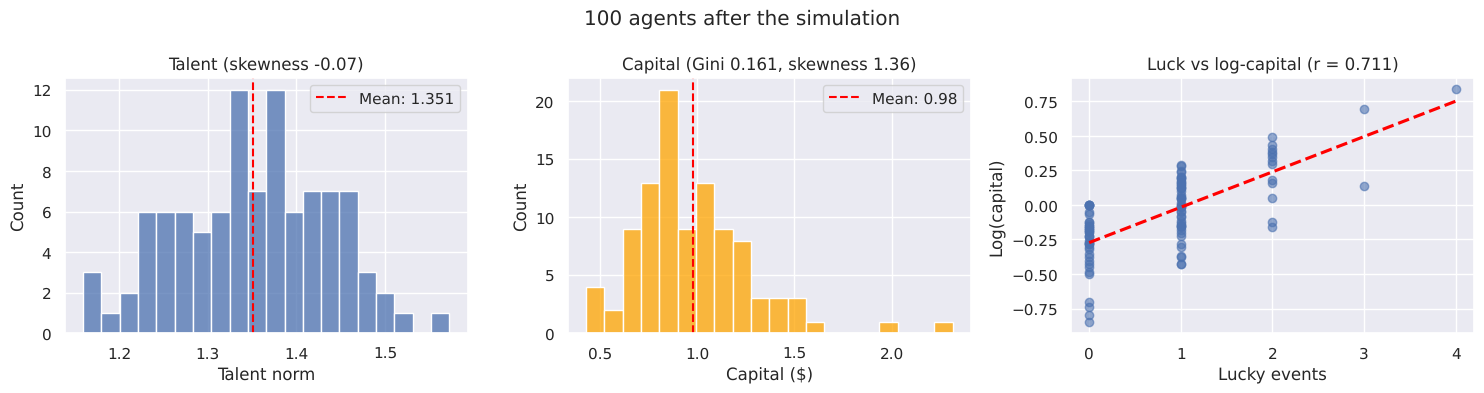

In [29]:
# Simulate 100 agents over 30 periods and plot the 3 panels.
n_agents_vis = 100
n_periods_vis = 30
seed_vis = 999
agents_vis = utils.create_population(n_agents=n_agents_vis, seed=seed_vis)
agents_vis = utils.run_simulation(
    agents_vis, n_periods=n_periods_vis, seed=seed_vis
)
df_vis = utils.get_results_dataframe(agents_vis)
utils.plot_talent_capital_luck(df_vis, figsize=(15, 4))

**Key observations**:

- The talent norm is close to symmetric, with a skewness of -0.07
- The capital is skewed to the right, with a skewness of 1.36 and a Gini of
  0.161
- The number of lucky events has a correlation of 0.711 with log-capital

**Guided usage**:

- Look at the 2 histograms: the same population gives a symmetric talent
  and a skewed capital
- Observe the right panel: agents with the same number of lucky events
  still differ, because talents and unlucky events also matter

In [30]:
hintros.print_obj_info(utils.plot_talent_capital_luck)

- `plot_talent_capital_luck(df: pandas.DataFrame, *, figsize: Optional[Tuple[float, float]] = None) -> None`  
  Plot the talent distribution, the capital distribution, and luck vs capital...

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask537_Review_students_research_projects/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_utils.py#L866


# Part 6: Bayesian estimate of the effect of luck

## Cell 6.1: Fitting the model

- The model regresses log-capital on the lucky events and the 3 talents:

$$\log(\text{capital}_i) = \alpha + \beta_{\text{luck}} \cdot \text{lucky}_i
  + \beta_{\text{intensity}} \cdot \text{intensity}_i
  + \beta_{\text{iq}} \cdot \text{iq}_i
  + \beta_{\text{networking}} \cdot \text{networking}_i + \varepsilon_i$$

- $\beta_{\text{luck}}$ is the change in log-capital from one more lucky
  event at fixed talent
- All priors are N(0, 1), and $\sigma$ has a half-normal prior
- PyMC and ArviZ are needed only for this part

In [31]:
# Simulate 100 agents over 80 periods, the data for the model.
n_agents_bayes = 100
agents_bayes = utils.create_population(n_agents=n_agents_bayes, seed=seed)
agents_bayes = utils.run_simulation(
    agents_bayes, n_periods=n_long_periods, seed=seed
)
df_bayes = utils.get_results_dataframe(agents_bayes)
print("df_bayes.shape=", df_bayes.shape)
# Outcome: 100 agents, with a Gini of 0.217.

df_bayes.shape= (100, 10)


In [32]:
# Sample the posterior with fewer draws than the default, to keep it fast.
draws = 500
tune = 500
model, idata = utils.fit_bayesian_luck_model(
    df_bayes, draws=draws, tune=tune, random_seed=seed
)
print("idata.posterior.sizes=", dict(idata.posterior.sizes))
# Outcome: 2 chains of 500 draws, with no divergences in the sampler log.

WARNING Using NumPy C-API based implementation for BLAS functions.


INFO  Auto-assigning NUTS sampler...


INFO  Initializing NUTS using jitter+adapt_diag...


INFO  Multiprocess sampling (2 chains in 2 jobs)


INFO  NUTS: [alpha, beta_luck, beta_intensity, beta_iq, beta_networking, sigma]


INFO  Sampling 2 chains for 500 tune and 500 draw iterations (1_000 + 1_000 draws total) took 4 seconds.


INFO  We recommend running at least 4 chains for robust computation of convergence diagnostics


idata.posterior.sizes= {'chain': 2, 'draw': 500}


## Cell 6.2: Summarizing the posterior

In [33]:
# Summarize the posterior of each parameter.
summary = utils.summarize_bayesian_fit(idata)
display(summary)
# Outcome: `beta_luck` has a posterior mean of 0.162 and a 94% interval of
# [0.124, 0.211], and every `r_hat` is at most 1.01.

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,-0.008,0.180,-0.314,0.346,0.007,0.006,624.0,565.0,1.00
beta_luck,0.162,0.023,0.124,0.211,0.001,0.001,816.0,597.0,1.00
beta_intensity,-0.530,0.251,-0.976,-0.039,0.009,0.007,789.0,739.0,1.00
beta_iq,-0.385,0.232,-0.866,-0.000,0.008,0.006,760.0,846.0,1.01
beta_networking,-0.222,0.231,-0.662,0.212,0.008,0.007,835.0,642.0,1.00
sigma,0.326,0.025,0.281,0.370,0.001,0.001,939.0,595.0,1.01


## Cell 6.3: Posterior predictive check

In [34]:
# Compare the observed log-capital with the model's predictions.
ppc_results = utils.posterior_predictive_check(model, idata, df_bayes)
df_ppc = pd.DataFrame(
    {
        "y_obs": ppc_results["y_obs"],
        "y_pred_mean": ppc_results["y_pred_mean"],
        "y_pred_std": ppc_results["y_pred_std"],
    }
)
display(df_ppc.head())
# Outcome: one row per agent, with a predictive standard deviation of about
# 0.33 for everyone, close to the posterior of `sigma`.

INFO  Sampling: [y_obs]


,y_obs,y_pred_mean,y_pred_std
0,-0.675640,-0.397612,0.327031
1,-0.716884,-0.327015,0.334013
2,-0.228326,0.090153,0.334156
3,-0.022799,-0.083566,0.328672
4,-0.916018,-0.174852,0.330961


**Key observations**:

- One more lucky event raises log-capital by about 0.16 at fixed talent,
  i.e., capital by about 18%, and the interval is far from 0
- The 3 talent coefficients are negative, but they are not the effect of
  talent: `intensity` and `iq` also change the number of lucky events, so
  holding lucky events fixed removes part of their effect
- The observed log-capital is within 2 predictive standard deviations of
  the predicted mean for 97 of the 100 agents

In [35]:
hintros.print_obj_info(utils.fit_bayesian_luck_model)

- `fit_bayesian_luck_model(df: pandas.DataFrame, *, draws: int = 1000, tune: int = 1000, target_accept: float = 0.9, random_seed: int = 42) -> Tuple[ForwardRef('pm.Model'), ForwardRef('az.InferenceData')]`  
  Fit a Bayesian regression model to estimate causal effect of luck on capital...

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask537_Review_students_research_projects/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_utils.py#L658


## Summary: The Mental Model

- An agent's capital is the product of the factors of the events it met, so
  the order and the number of events matter, not only the talents
- Talents are drawn close to symmetric, but multiplying random factors makes
  the capital skewed, and inequality grows with the number of periods
- A policy changes the starting capital, and the same random events then
  play out on top of it
- Regressing log-capital on lucky events and talents measures the effect of
  luck at fixed talent, with a posterior that shows its uncertainty